In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef
)

In [10]:
columns = [
    "class", "cap_shape", "cap_surface", "cap_color",
    "bruises", "odor", "gill_attachment", "gill_spacing",
    "gill_size", "gill_color", "stalk_shape", "stalk_root",
    "stalk_surface_above", "stalk_surface_below",
    "stalk_color_above", "stalk_color_below", "veil_type",
    "veil_color", "ring_number", "ring_type",
    "spore_print_color", "population", "habitat"
]

url = (
    "https://archive.ics.uci.edu/ml/"
    "machine-learning-databases/mushroom/agaricus-lepiota.data"
)

df = pd.read_csv(url, header=None, names=columns)

print(df.head())
print("Dataset shape:", df.shape)

  class cap_shape cap_surface cap_color bruises odor gill_attachment  \
0     p         x           s         n       t    p               f   
1     e         x           s         y       t    a               f   
2     e         b           s         w       t    l               f   
3     p         x           y         w       t    p               f   
4     e         x           s         g       f    n               f   

  gill_spacing gill_size gill_color  ... stalk_surface_below  \
0            c         n          k  ...                   s   
1            c         b          k  ...                   s   
2            c         b          n  ...                   s   
3            c         n          n  ...                   s   
4            w         b          k  ...                   s   

  stalk_color_above stalk_color_below veil_type veil_color ring_number  \
0                 w                 w         p          w           o   
1                 w               

In [11]:
print(df.info())

print("\nMissing values:")
print(df.isnull().sum())

print("\nClass distribution:")
print(df["class"].value_counts())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8124 entries, 0 to 8123
Data columns (total 23 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   class                8124 non-null   object
 1   cap_shape            8124 non-null   object
 2   cap_surface          8124 non-null   object
 3   cap_color            8124 non-null   object
 4   bruises              8124 non-null   object
 5   odor                 8124 non-null   object
 6   gill_attachment      8124 non-null   object
 7   gill_spacing         8124 non-null   object
 8   gill_size            8124 non-null   object
 9   gill_color           8124 non-null   object
 10  stalk_shape          8124 non-null   object
 11  stalk_root           8124 non-null   object
 12  stalk_surface_above  8124 non-null   object
 13  stalk_surface_below  8124 non-null   object
 14  stalk_color_above    8124 non-null   object
 15  stalk_color_below    8124 non-null   object
 16  veil_t

In [12]:
# Replace the question mark with a proper missing value
df = df.replace("?", np.nan)

# Check duplicate rows
print("Duplicates before cleaning:", df.duplicated().sum())

# Remove duplicate rows
df = df.drop_duplicates().copy()

print("Shape after removing duplicates:", df.shape)

Duplicates before cleaning: 0
Shape after removing duplicates: (8124, 23)


In [13]:
# 1 means poisonous, 0 means edible
y = (df["class"] == "p").astype(int)

# Remove the target column from the input features
X = df.drop(columns=["class"])

print("Features:", X.shape)
print("Target:", y.shape)

Features: (8124, 22)
Target: (8124,)


class
0    4208
1    3916
Name: count, dtype: int64

Class percentages:
class
0    51.797144
1    48.202856
Name: proportion, dtype: float64


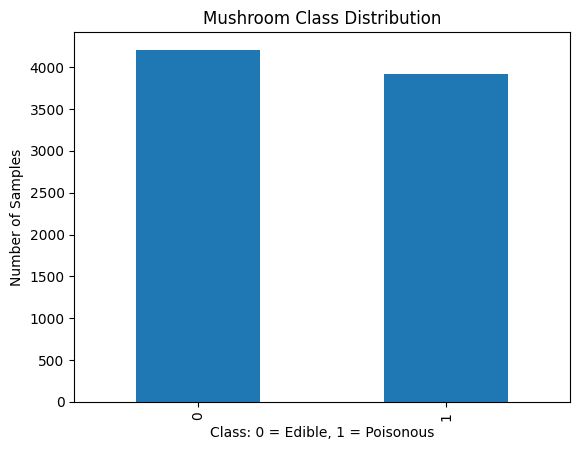

In [14]:
print(y.value_counts())

print("\nClass percentages:")
print(y.value_counts(normalize=True) * 100)

y.value_counts().plot(kind="bar")
plt.title("Mushroom Class Distribution")
plt.xlabel("Class: 0 = Edible, 1 = Poisonous")
plt.ylabel("Number of Samples")
plt.show()

In [15]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 6499
Testing samples: 1625


In [16]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "KNN": KNeighborsClassifier(

        n_neighbors=5
    ),

    "Naive Bayes": GaussianNB(),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    )
}

In [17]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

categorical_features = X.columns.tolist()

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("encoder", OneHotEncoder(
                    handle_unknown="ignore",
                    sparse_output=False
                )),
                ("scaler", StandardScaler())
            ]),
            categorical_features
        )
    ]
)

print("Preprocessor created successfully!")

Preprocessor created successfully!


In [18]:
results = []

for model_name, model in models.items():

    # Combine preprocessing and model
    pipeline = Pipeline([
        ("preprocessing", preprocessor),
        ("classifier", model)
    ])

    # Train the model
    pipeline.fit(X_train, y_train)

    # Predict classes
    y_pred = pipeline.predict(X_test)

    # Predict probabilities for AUC
    y_prob = pipeline.predict_proba(X_test)[:, 1]

    # Calculate all required metrics
    accuracy = accuracy_score(y_test, y_pred)

    auc = roc_auc_score(y_test, y_prob)

    precision = precision_score(
        y_test, y_pred, zero_division=0
    )

    recall = recall_score(
        y_test, y_pred, zero_division=0
    )

    f1 = f1_score(
        y_test, y_pred, zero_division=0
    )

    mcc = matthews_corrcoef(y_test, y_pred)

    # Store the results
    results.append({
        "Model": model_name,
        "Accuracy": accuracy,
        "AUC": auc,
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
        "MCC": mcc
    })

    print(model_name, "completed")

Logistic Regression completed
Decision Tree completed
KNN completed
Naive Bayes completed
Random Forest completed


In [19]:
categorical_features = X.columns.tolist()
preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("encoder", OneHotEncoder(
                    handle_unknown="ignore",
                    sparse_output=False
                )),
                ("scaler", StandardScaler())
            ]),
            categorical_features
        )
    ]
)

In [20]:
results_df = pd.DataFrame(results)

print(results_df.round(4))

                 Model  Accuracy     AUC  Precision  Recall      F1     MCC
0  Logistic Regression    1.0000  1.0000     1.0000  1.0000  1.0000  1.0000
1        Decision Tree    1.0000  1.0000     1.0000  1.0000  1.0000  1.0000
2                  KNN    0.9988  1.0000     1.0000  0.9974  0.9987  0.9975
3          Naive Bayes    0.9526  0.9963     0.9124  0.9974  0.9530  0.9091
4        Random Forest    1.0000  1.0000     1.0000  1.0000  1.0000  1.0000


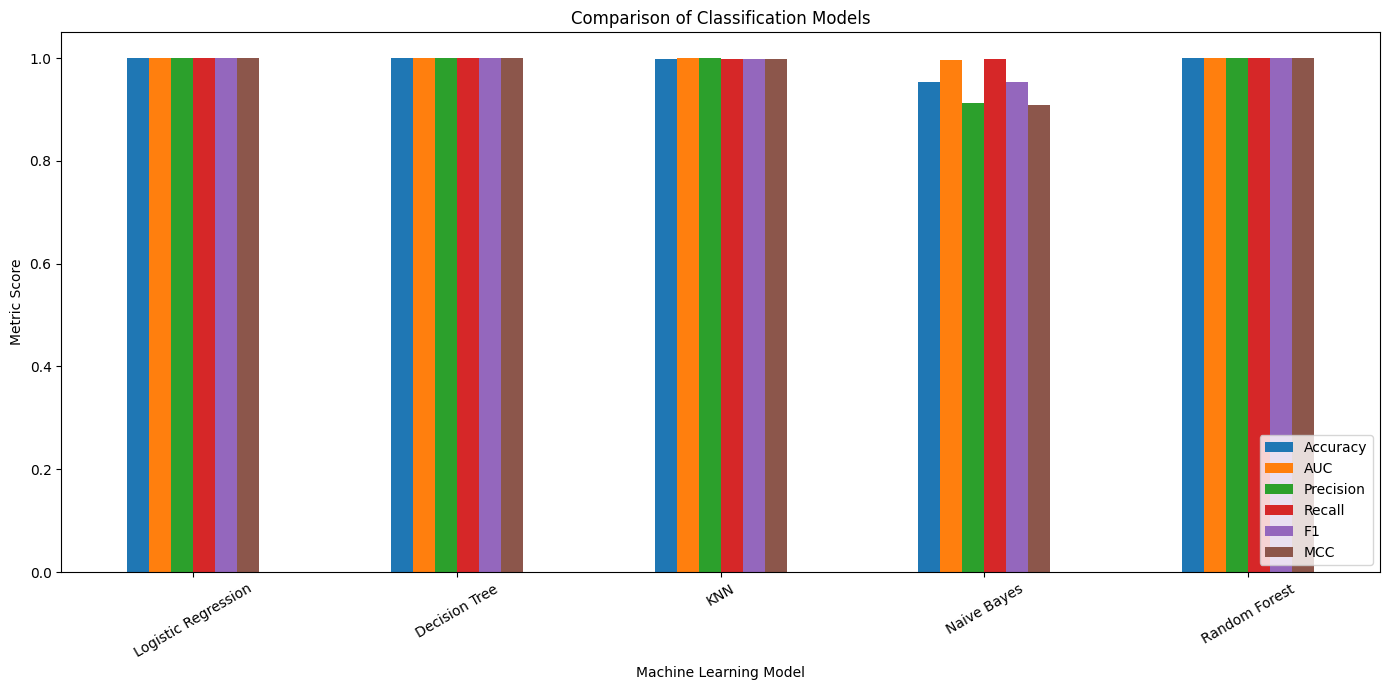

In [21]:
metrics = [
    "Accuracy",
    "AUC",
    "Precision",
    "Recall",
    "F1",
    "MCC"
]

results_df.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(14, 7)
)

plt.title("Comparison of Classification Models")
plt.ylabel("Metric Score")
plt.xlabel("Machine Learning Model")
plt.xticks(rotation=30)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [22]:
winner = results_df.loc[
    results_df["F1"].idxmax()
]

print("Overall winner based on F1:")
print(winner)

Overall winner based on F1:
Model        Logistic Regression
Accuracy                     1.0
AUC                          1.0
Precision                    1.0
Recall                       1.0
F1                           1.0
MCC                          1.0
Name: 0, dtype: object


In [23]:
test_data = X_test.copy()

test_data["target"] = y_test

test_data.to_csv("test_data.csv", index=False)

results_df.to_csv("model_results.csv", index=False)

print("Test data and model results saved.")

Test data and model results saved.


In [24]:
import os

print("Current folder:", os.getcwd())
print("Files in current folder:")
print(os.listdir())

Current folder: /content
Files in current folder:
['.config', 'model_results.csv', 'test_data.csv', 'model', 'sample_data']


In [25]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000, random_state=42
    ),
    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "Naive Bayes": GaussianNB(),
    "Random Forest": RandomForestClassifier(
        n_estimators=100, random_state=42
    )
}

print("All five models are defined!")

All five models are defined!


In [26]:
import pandas as pd
import numpy as np

columns = [
    "class", "cap_shape", "cap_surface", "cap_color", "bruises",
    "odor", "gill_attachment", "gill_spacing", "gill_size",
    "gill_color", "stalk_shape", "stalk_root",
    "stalk_surface_above", "stalk_surface_below",
    "stalk_color_above", "stalk_color_below", "veil_type",
    "veil_color", "ring_number", "ring_type",
    "spore_print_color", "population", "habitat"
]

url = "https://archive.ics.uci.edu/ml/machine-learning-databases/mushroom/agaricus-lepiota.data"

df = pd.read_csv(url, header=None, names=columns)

df = df.replace("?", np.nan)
df = df.drop_duplicates().copy()

y = (df["class"] == "p").astype(int)
X = df.drop(columns=["class"])

print("Dataset loaded successfully!")
print("Features:", X.shape)
print("Target:", y.shape)

Dataset loaded successfully!
Features: (8124, 22)
Target: (8124,)


In [27]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Train and test data created!")

Train and test data created!


In [28]:

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

categorical_features = X.columns.tolist()

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("encoder", OneHotEncoder(
                    handle_unknown="ignore",
                    sparse_output=False
                )),
                ("scaler", StandardScaler())
            ]),
            categorical_features
        )
    ]
)

print("Preprocessor created successfully!")


Preprocessor created successfully!


In [29]:

import os
import joblib
from sklearn.pipeline import Pipeline

os.makedirs("model", exist_ok=True)

for model_name, model in models.items():
    print("Training:", model_name)

    pipeline = Pipeline([
        ("preprocessing", preprocessor),
        ("classifier", model)
    ])

    pipeline.fit(X_train, y_train)

    filename = model_name.lower().replace(" ", "_") + ".joblib"
    joblib.dump(pipeline, os.path.join("model", filename))

    print("Saved:", filename)

print("All five models trained and saved!")


Training: Logistic Regression
Saved: logistic_regression.joblib
Training: Decision Tree
Saved: decision_tree.joblib
Training: KNN
Saved: knn.joblib
Training: Naive Bayes
Saved: naive_bayes.joblib
Training: Random Forest
Saved: random_forest.joblib
All five models trained and saved!


In [30]:
import os
print(os.listdir("model"))

['decision_tree.joblib', 'logistic_regression.joblib', 'random_forest.joblib', 'knn.joblib', 'naive_bayes.joblib']


In [31]:
import shutil

shutil.make_archive("saved_models", "zip", "model")

print("Model ZIP created!")

Model ZIP created!
